In [1]:
from __future__ import annotations

from pathlib import Path
import json
import numpy as np
import rasterio
from rasterio.transform import Affine
from rasterio.warp import reproject, Resampling
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from rasterio.windows import Window
from rasterio.windows import bounds as window_bounds
import json



# Re-usable Function Definitions

In [2]:
def load_roi_template(json_path: str | Path):
    
    '''
    Read roi_20m_metadata.json and extract the necessary information for reprojection.

    Returns:
    - dst_crs: The coordinate reference system of the target grid.
    - dst_transform: The affine transformation for the target grid.
    - dst_width: The width of the target grid in pixels.
    - dst_height: The height of the target grid in pixels.
    - bounds: The spatial bounds of the target grid (optional, if available in the JSON).
    '''

    grid_json = json.loads(Path(json_path).read_text())
    dst_crs = grid_json["crs"]

    t = grid_json["grid20"]["transform"]
    # Il tuo JSON ha: [x0, px, 0, y0, 0, -px]
    dst_transform = Affine(t[1], t[2], t[0], t[4], t[5], t[3])

    dst_width = int(grid_json["grid20"]["width"])
    dst_height = int(grid_json["grid20"]["height"])
    bounds = grid_json.get("bounds", None)

    return dst_crs, dst_transform, dst_width, dst_height, bounds

In [3]:
def find_band_jp2(safe_path: str | Path, band: str, resolution_m: int) -> Path:
    
    """
    Find the JP2 file for a specific band and resolution in a Sentinel-2 SAFE directory.

    Parameters:
    - safe_path: Path to the SAFE directory.
    - band: Band name (e.g., "B04", "B08").
    - resolution_m: Desired resolution in meters (10 or 20).

    Returns:
    - Path to the JP2 file for the specified band and resolution.

    Raises:
    - FileNotFoundError: If the SAFE directory or the specified band at the given resolution is not found.
    - ValueError: If the resolution is not 10 or 20 meters
    """

    safe_path = Path(safe_path)
    if not safe_path.exists():
        raise FileNotFoundError(f"SAFE not found: {safe_path}")

    band = band.upper()
    if resolution_m not in (10, 20):
        raise ValueError("resolution_m must be 10 or 20")

    r_folder = "R10m" if resolution_m == 10 else "R20m"

    # pattern robusti (alcuni SAFE possono avere variazioni minime nel naming)
    patterns = [
        f"GRANULE/*/IMG_DATA/{r_folder}/*_{band}_{resolution_m}m.jp2",
        f"GRANULE/*/IMG_DATA/{r_folder}/*{band}_{resolution_m}m.jp2",
    ]

    for pat in patterns:
        hits = list(safe_path.glob(pat))
        if hits:
            return hits[0]

    raise FileNotFoundError(f"Band {band} at {resolution_m}m not found in SAFE: {safe_path}")

In [4]:
def find_scl_jp2(safe_path: str | Path) -> Path:
    """
    Find the JP2 file for the Scene Classification Layer (SCL) at 20m resolution in a Sentinel-2 SAFE directory.
    """
    return find_band_jp2(safe_path, "SCL", 20)

In [5]:
def warp_jp2_to_template(
    jp2_path: str | Path,
    dst_crs: str,
    dst_transform: Affine,
    dst_width: int,
    dst_height: int,
    *,
    resampling: str = "bilinear",
    dst_dtype=np.float32,
    dst_nodata=np.nan,
    scale_reflectance: bool = False,
) -> np.ndarray:
    
    """
    Read a JP2 file, reproject and resample it to match the target grid defined by the provided parameters.

    Parameters:
    - jp2_path: Path to the input JP2 file.
    - dst_crs: The coordinate reference system of the target grid (e.g., "EPSG:4326").
    - dst_transform: The affine transformation for the target grid.
    - dst_width: The width of the target grid in pixels.
    - dst_height: The height of the target grid in pixels.
    - resampling: Resampling method to use ("nearest", "bilinear", "cubic", "average").
    - dst_dtype: Data type for the output array (default: np.float32).
    - dst_nodata: NoData value for the output array (default: np.nan).
    - scale_reflectance: If True, scale the output values by 1/10000 (useful for Sentinel-2 reflectance bands).

    Returns:
    - A 2D NumPy array containing the reprojected and resampled data.

    Raises:
    - FileNotFoundError: If the input JP2 file is not found.
    - ValueError: If an unsupported resampling method is specified.
    """
    
    jp2_path = Path(jp2_path)
    if not jp2_path.exists():
        raise FileNotFoundError(jp2_path)

    resampling_map = {
        "nearest": Resampling.nearest,
        "bilinear": Resampling.bilinear,
        "cubic": Resampling.cubic,
        "average": Resampling.average,
    }
    if resampling not in resampling_map:
        raise ValueError(f"Unsupported resampling='{resampling}'. Use one of {list(resampling_map)}.")

    dst = np.full((dst_height, dst_width), dst_nodata, dtype=dst_dtype)

    with rasterio.open(jp2_path) as src:
        src_arr = src.read(1)

        reproject(
            source=src_arr,
            destination=dst,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            dst_nodata=dst_nodata,
            resampling=resampling_map[resampling],
        )

    if scale_reflectance:
        dst = dst.astype(np.float32) / 10000.0

    return dst

In [6]:
def extract_band_to_roi(
    safe_path: str | Path,
    band: str,
    *,
    resolution_m: int,
    template,
    resampling: str,
    scale_reflectance: bool,
    dst_dtype=np.float32,
    dst_nodata=np.nan,
) -> np.ndarray:
    
    """
    Extract a specific band from a Sentinel-2 SAFE directory, reproject and resample it to match the target grid defined by the provided template.
    
    Parameters:
    - safe_path: Path to the SAFE directory.
    - band: Band name (e.g., "B04", "B08").
    - resolution_m: Desired resolution in meters (10 or 20).
    - template: A tuple containing (dst_crs, dst_transform, dst_width, dst_height) for the target grid.
    - resampling: Resampling method to use ("nearest",
    - scale_reflectance: If True, scale the output values by 1/10000 (useful for Sentinel-2 reflectance bands).
    - dst_dtype: Data type for the output array (default: np.float32).
    - dst_nodata: NoData value for the output array (default: np.nan).

    Returns:
    - A 2D NumPy array containing the extracted, reprojected, and resampled band data.
    """

    dst_crs, dst_transform, dst_width, dst_height = template
    jp2 = find_band_jp2(safe_path, band, resolution_m)

    return warp_jp2_to_template(
        jp2,
        dst_crs, dst_transform, dst_width, dst_height,
        resampling=resampling,
        dst_dtype=dst_dtype,
        dst_nodata=dst_nodata,
        scale_reflectance=scale_reflectance,
    )

In [7]:
def build_feature_stack(safe_path, template):
    """
    Build a feature stack for a Sentinel-2 scene by extracting the relevant bands and computing NDVI, all reprojected to a common grid defined by the template.
    Feature order:
    [B05, B06, B07, B8A, B11, B12, NDVI]

    Parameters:
    - safe_path: Path to the SAFE directory.
    - template: A tuple containing (dst_crs, dst_transform, dst_width, dst_height) for the target grid.

    Returns:
    - X_stack: A 3D NumPy array (H, W, 7) containing the stacked features for the bands and NDVI.
    - scl: A 2D NumPy array (H, W) containing the Scene Classification Layer (SCL) values.
    """

    dst_crs, dst_transform, dst_w, dst_h = template

    # ---- 20m reflectance bands ----
    bands_20m = ["B05", "B06", "B07", "B8A", "B11", "B12"]
    band_arrays = []

    for band in bands_20m:
        arr = extract_band_to_roi(
            safe_path,
            band,
            resolution_m=20,
            template=template,
            resampling="bilinear",
            scale_reflectance=True,
        )
        band_arrays.append(arr)

    # ---- NDVI from B04/B08 ----
    red_20m = extract_band_to_roi(
        safe_path,
        "B04",
        resolution_m=10,   # originale 10m
        template=template, # warp su griglia 20m
        resampling="bilinear",
        scale_reflectance=True,
    )

    nir_20m = extract_band_to_roi(
        safe_path,
        "B08",
        resolution_m=10,
        template=template,
        resampling="bilinear",
        scale_reflectance=True,
    )

    ndvi_20m = (nir_20m - red_20m) / (nir_20m + red_20m + 1e-6)
    ndvi_20m = np.clip(ndvi_20m, -1, 1)

    # ---- Stack finale ----
    X_stack = np.dstack(band_arrays + [ndvi_20m]).astype(np.float32)

    # ---- SCL ----
    scl = extract_band_to_roi(
        safe_path,
        "SCL",
        resolution_m=20,
        template=template,
        resampling="nearest",
        scale_reflectance=False,
        dst_dtype=np.uint8,
        dst_nodata=255,
    )

    return X_stack, scl


In [8]:
cross_path = Path("./cross-scene")
if not cross_path.exists():
    raise FileNotFoundError(f"Directory {cross_path} does not exist.")

cross_year = next(cross_path.glob("S2A_MSIL2A_20211013T101951_N0500_R065_T32TMR_20230115T052455.SAFE"))
cross_season = next(cross_path.glob("S2B_MSIL2A_20240823T101559_N0511_R065_T32TMR_20240823T145151.SAFE"))
if not cross_year.exists() or not cross_season.exists():
    raise FileNotFoundError("Required SAFE directories for cross-scene analysis not found.")

# 1) Carica template ROI
dst_crs, dst_transform, dst_w, dst_h, bounds = load_roi_template("roi_20m_metadata.json")
template = (dst_crs, dst_transform, dst_w, dst_h)

# 2) Prova a estrarre una banda 20m e SCL da una SAFE
b11 = extract_band_to_roi(cross_year, "B11", resolution_m=20, template=template,
                          resampling="bilinear", scale_reflectance=True)

scl = extract_band_to_roi(cross_year, "SCL", resolution_m=20, template=template,
                          resampling="nearest", scale_reflectance=False,
                          dst_dtype=np.uint8, dst_nodata=255)

print(b11.shape, b11.min(), b11.max())
print(np.unique(scl)[:20])


(1000, 1000) 0.1068 1.6182
[ 2  3  4  5  6  7  8  9 10]


In [9]:
def load_singleband_geotiff(tif_path: str | Path) -> tuple[np.ndarray, dict]:
    """
    Load a single-band GeoTIFF as a float32 numpy array.

    Returns
    -------
    arr : np.ndarray
        2D array (H, W) with the raster values.
    meta : dict
        Minimal metadata useful for sanity checks (crs, transform, dtype, nodata, shape).
    """
    tif_path = Path(tif_path)
    if not tif_path.exists():
        raise FileNotFoundError(f"GeoTIFF not found: {tif_path}")

    with rasterio.open(tif_path) as src:
        arr = src.read(1).astype(np.float32)
        meta = {
            "crs": str(src.crs),
            "transform": src.transform,
            "dtype": str(arr.dtype),
            "nodata": src.nodata,
            "shape": arr.shape,
        }
    return arr, meta


def load_and_clean_lai(lai_tif_path: str | Path, clip_max: float = 6.0) -> tuple[np.ndarray, dict]:
    """
    Load a SNAP LAI GeoTIFF and apply the same cleaning used across all studies:
      - set negative values to NaN (retrieval artifacts)
      - clip to [0, clip_max] (conservative physical range)

    Returns
    -------
    lai_clean : (H,W) float32
    meta : dict with crs/transform/shape for sanity checks
    """
    lai_raw, meta = load_singleband_geotiff(lai_tif_path)
    lai_clean = lai_raw.copy().astype(np.float32)
    lai_clean[lai_clean < 0] = np.nan
    lai_clean = np.clip(lai_clean, 0.0, clip_max)
    return lai_clean, meta


In [10]:
def build_mask(
    scl: np.ndarray,
    lai_clean: np.ndarray | None = None,
    keep_classes: list[int] = [4, 5, 6, 7],
) -> np.ndarray:
    """
    Build a boolean mask of valid pixels.
    - keeps only selected SCL classes (surface-like pixels)
    - optionally requires LAI to be finite (for evaluation/training consistency)
    """
    m = np.isin(scl, keep_classes)
    if lai_clean is not None:
        m = m & np.isfinite(lai_clean)
    return m


### Plots

In [43]:
import numpy as np
import matplotlib.pyplot as plt

FEATURE_NAMES = ["B05","B06","B07","B8A","B11","B12","NDVI"]
FEATURE_INDEX = {k:i for i,k in enumerate(FEATURE_NAMES)}

def compute_stretch_stats(X_stack, channels, pmin=2, pmax=98, mask=None):
    """
    Compute per-channel percentile stretch stats on a reference scene.

    Parameters
    ----------
    X_stack : (H,W,C) array
    channels : tuple/list of feature names, e.g. ("B12","B8A","B05")
    pmin/pmax : percentiles for robust stretch
    mask : optional (H,W) bool mask to restrict stats (e.g. LAI>4 area)

    Returns
    -------
    stats : dict {channel_name: (lo, hi)}
    """
    stats = {}
    for ch in channels:
        idx = FEATURE_INDEX[ch]
        arr = X_stack[..., idx]
        if mask is not None:
            arr = arr[mask]
        arr = arr[np.isfinite(arr)]
        lo, hi = np.percentile(arr, [pmin, pmax])
        stats[ch] = (float(lo), float(hi))
    return stats


def make_composite_image(
    X_stack,
    channels=("B12","B8A","B05"),
    stretch_stats=None,
    pmin=2,
    pmax=98,
    mask=None,
    gamma=1.0,
):
    """
    Create an RGB-like composite from selected features in X_stack, with consistent stretching.

    Parameters
    ----------
    X_stack : (H,W,C) float array
        Your feature stack: [B05,B06,B07,B8A,B11,B12,NDVI]
    channels : tuple(str,str,str)
        Which features map to (R,G,B) in the composite.
        Recommended for your project:
          - ("B12","B8A","B05")  # SWIR-NIR-RedEdge (structure & water content emphasis)
          - ("B11","B8A","B05")  # SWIR1-NIR-RedEdge
          - ("B8A","B06","B05")  # NIR-RedEdge-RedEdge (veg vigor-ish)
    stretch_stats : dict or None
        If provided, uses these (lo,hi) per channel to stretch consistently across scenes.
        If None, computes on-the-fly from this X_stack (not ideal for comparison across scenes).
    pmin/pmax : percentiles used only if stretch_stats is None
    mask : optional (H,W) bool mask
        If provided, pixels outside mask are set to NaN (shown as black).
        Useful to focus only on LAI>4.
    gamma : float
        Optional gamma correction after stretching (1.0 = none). Keep 1.0 unless needed.

    Returns
    -------
    rgb : (H,W,3) float array in [0,1]
    used_stats : dict {channel: (lo,hi)}
    """
    H, W, _ = X_stack.shape
    if stretch_stats is None:
        used_stats = compute_stretch_stats(X_stack, channels, pmin=pmin, pmax=pmax, mask=mask)
    else:
        used_stats = stretch_stats

    rgb = np.zeros((H, W, 3), dtype=np.float32)

    for k, ch in enumerate(channels):
        idx = FEATURE_INDEX[ch]
        arr = X_stack[..., idx].astype(np.float32)

        if mask is not None:
            arr = np.where(mask, arr, np.nan)

        lo, hi = used_stats[ch]
        # robust stretch
        x = (arr - lo) / (hi - lo + 1e-6)
        x = np.clip(x, 0, 1)

        if gamma != 1.0:
            x = np.power(x, 1.0/gamma)

        # replace NaNs outside mask with 0 for display
        x = np.nan_to_num(x, nan=0.0)
        rgb[..., k] = x

    return rgb, used_stats


def plot_composites(
    composites,
    titles,
    figsize=(18,6),
):
    """
    Plot multiple composite images side-by-side.

    composites: list of (H,W,3) arrays
    titles: list of strings
    """
    n = len(composites)
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(composites, titles), start=1):
        plt.subplot(1, n, i)
        plt.imshow(img)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


# Starting here

In [11]:
# --- Paht definitions ---
train_safe = Path("./S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE")
cross_path = Path("./cross-scene")

cross_season = next(cross_path.glob("S2A_MSIL2A_20211013T101951_N0500_R065_T32TMR_20230115T052455.SAFE"))
cross_year = next(cross_path.glob("S2B_MSIL2A_20240823T101559_N0511_R065_T32TMR_20240823T145151.SAFE"))

# Roi Building

In [12]:
roi_km = 20
roi_m = roi_km * 1000

target_resolution = 200 #sliding window search
native_resolution = 10 #ndvi is calcuted at 10m

roi_px_200m = roi_m // target_resolution
print(f"ROI size in pixels at {target_resolution}m resolution: {roi_px_200m}x{roi_px_200m}")

ROI size in pixels at 200m resolution: 100x100


In [13]:
train_b04_10m = find_band_jp2(train_safe, "B04", 10)
train_b08_10m = find_band_jp2(train_safe, "B08", 10)
print("Train B04 JP2 path:", train_b04_10m)
print("Train B08 JP2 path:", train_b08_10m)

Train B04 JP2 path: S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B04_10m.jp2
Train B08 JP2 path: S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B08_10m.jp2


In [15]:
with rasterio.open(train_b04_10m) as src_red:
    H, W = src_red.height, src_red.width
    red_10m = src_red.read(1).astype(np.float32)

    H_ds = int(H * native_resolution / target_resolution)
    W_ds = int(W * native_resolution / target_resolution)

    red_ds = src_red.read(1, out_shape=(H_ds, W_ds), resampling=Resampling.bilinear).astype(np.float32)

    transform_ds = src_red.transform * src_red.transform.scale((W / W_ds), (H / H_ds))
    crs = src_red.crs

with rasterio.open(train_b08_10m) as src_nir:
    nir_ds = src_nir.read(1, out_shape=(H_ds, W_ds), resampling=Resampling.bilinear).astype(np.float32)

ndvi_ds = (nir_ds - red_ds) / (nir_ds + red_ds + 1e-6)

mask = np.isfinite(ndvi_ds) & (ndvi_ds > -0.2) & (ndvi_ds < 1.0) & (red_ds > 0) & (nir_ds > 0)
ndvi_ds_masked = np.where(mask, ndvi_ds, np.nan)
print("NDVI_ds shape:", ndvi_ds_masked.shape, "min/max:", float(np.nanmin(ndvi_ds_masked)), float(np.nanmax(ndvi_ds_masked)))

NDVI_ds shape: (549, 549) min/max: -0.19775910675525665 0.738421618938446


Best window top-left @200m: x=160, y=91, mean NDVI=0.5774


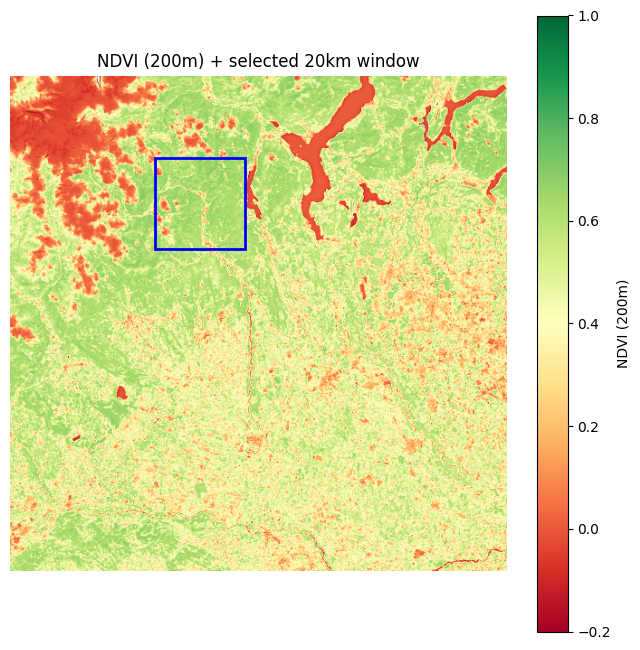

In [16]:
def window_with_highest_ndvi(ndvi_array, window_size):
    valid = np.isfinite(ndvi_array).astype(np.float32)
    a = np.nan_to_num(ndvi_array, nan=0.0).astype(np.float32)

    S = np.cumsum(np.cumsum(a, axis=0), axis=1)
    C = np.cumsum(np.cumsum(valid, axis=0), axis=1)

    def box_sum(M):
        return (M[window_size:, window_size:]
                - M[:-window_size, window_size:]
                - M[window_size:, :-window_size]
                + M[:-window_size, :-window_size])

    sum_ndvi = box_sum(S)
    count_valid = box_sum(C)
    mean_ndvi = np.where(count_valid > 0, sum_ndvi / count_valid, -np.inf)

    y, x = np.unravel_index(np.argmax(mean_ndvi), mean_ndvi.shape)
    return x, y, float(mean_ndvi[y, x])

x0_200m, y0_200m, max_ndvi_200m = window_with_highest_ndvi(ndvi_ds_masked, roi_px_200m)
print(f"Best window top-left @200m: x={x0_200m}, y={y0_200m}, mean NDVI={max_ndvi_200m:.4f}")

plt.figure(figsize=(8,8))
plt.imshow(ndvi_ds_masked, cmap="RdYlGn", vmin=-0.2, vmax=1.0)
plt.colorbar(label="NDVI (200m)")
rect = plt.Rectangle((x0_200m, y0_200m), roi_px_200m, roi_px_200m, edgecolor="blue", facecolor="none", linewidth=2)
plt.gca().add_patch(rect)
plt.title("NDVI (200m) + selected 20km window")
plt.axis("off")
plt.show()


In [17]:
#Scale factor between 20m and target resolution of 200m
scale_factor_20m = target_resolution // 20

# Scaling x0 and y0 coordinates from 200m to 20m grid
x0_20m = int(x0_200m * scale_factor_20m)
y0_20m = int(y0_200m * scale_factor_20m)

roi_px_20m = roi_px_200m * scale_factor_20m
print(f"ROI size in pixels at 20m resolution: {roi_px_20m}x{roi_px_20m}")

ROI size in pixels at 20m resolution: 1000x1000


In [18]:
train_b05_20m = find_band_jp2(train_safe, "B05", 20)

with rasterio.open(train_b05_20m) as src20:
    window_20m = Window(x0_20m, y0_20m, roi_px_20m, roi_px_20m)
    roi_bounds_utm = window_bounds(window_20m, transform=src20.transform)
    roi_transform = src20.window_transform(window_20m)
    roi_crs = src20.crs.to_string()

roi_20m_data = {
    "crs": roi_crs,
    "bounds": {"xmin": roi_bounds_utm[0], "ymin": roi_bounds_utm[1], "xmax": roi_bounds_utm[2], "ymax": roi_bounds_utm[3]},
    "grid20": {"transform": roi_transform.to_gdal(), "width": int(roi_px_20m), "height": int(roi_px_20m)},
}

Path("roi_20m_metadata.json").write_text(json.dumps(roi_20m_data, indent=4))
print("Saved ROI template to roi_20m_metadata.json")
print("ROI bounds:", roi_20m_data["bounds"])
print("ROI grid20 transform:", roi_20m_data["grid20"]["transform"])

Saved ROI template to roi_20m_metadata.json
ROI bounds: {'xmin': 431960.0, 'ymin': 5061800.0, 'xmax': 451960.0, 'ymax': 5081800.0}
ROI grid20 transform: (431960.0, 20.0, 0.0, 5081800.0, 0.0, -20.0)


In [19]:
dst_crs, dst_transform, dst_w, dst_h, bounds = load_roi_template("roi_20m_metadata.json")
template = (dst_crs, dst_transform, dst_w, dst_h)

# Machine Learning Methods - Subject Study

## Feature Preparation

In [20]:
training_X, training_scl = build_feature_stack(train_safe, template)
print("Training feature stack shape:", training_X.shape)
print("Training SCL shape:", training_scl.shape)

training_lai_path = "LAI_ROI_20m.tif"
training_lai, lai_meta = load_and_clean_lai(training_lai_path)
print("Training LAI shape:", training_lai.shape)

mask_train = build_mask(training_scl, training_lai, keep_classes=[4, 5, 6, 7])

print("Mask shape:", mask_train.shape)
print("Valid fraction:", mask_train.mean())

Training feature stack shape: (1000, 1000, 7)
Training SCL shape: (1000, 1000)
Training LAI shape: (1000, 1000)
Mask shape: (1000, 1000)
Valid fraction: 0.949831


In [21]:
X_train = training_X[mask_train]
y_train = training_lai[mask_train]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("y_train stats:")
print("Min:", np.min(y_train))
print("Max:", np.max(y_train))
print("Mean:", np.mean(y_train))


X_train shape: (949831, 7)
y_train shape: (949831,)
y_train stats:
Min: 0.0
Max: 6.0
Mean: 2.8427057


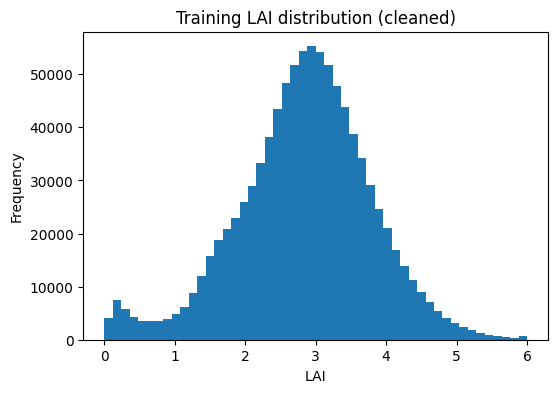

In [22]:
plt.figure(figsize=(6,4))
plt.hist(y_train, bins=50)
plt.title("Training LAI distribution (cleaned)")
plt.xlabel("LAI")
plt.ylabel("Frequency")
plt.show()


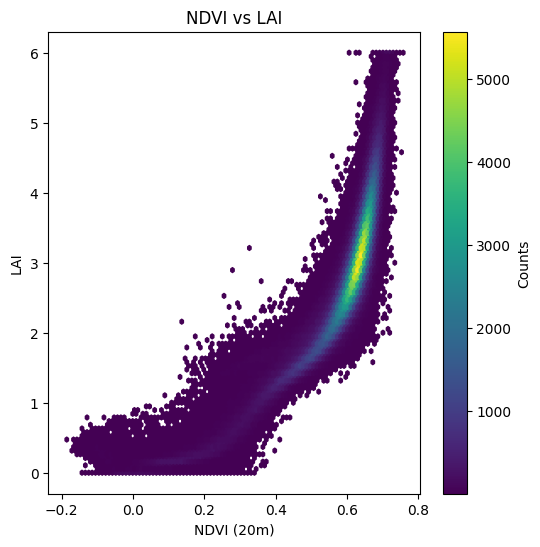

In [23]:
ndvi_train = X_train[:, -1]

plt.figure(figsize=(6,6))
plt.hexbin(ndvi_train, y_train, gridsize=100, cmap="viridis", mincnt=1)
plt.xlabel("NDVI (20m)")
plt.ylabel("LAI")
plt.colorbar(label="Counts")
plt.title("NDVI vs LAI")
plt.show()

## Random Forest

### Train-Test Split  pixel wise (Scikit-Learn)

In [24]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

print("Train size:", X_tr.shape)
print("Test size :", X_te.shape)

Train size: (759864, 7)
Test size : (189967, 7)


R²: 0.9972531670366688
RMSE: 0.04977305463076761
Bias: -0.00014430940861775155


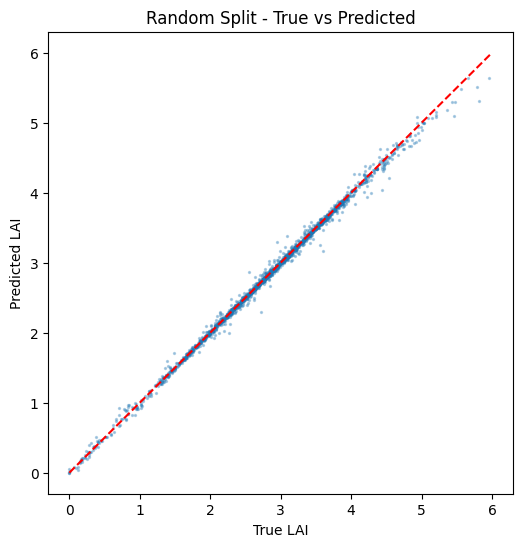

In [25]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

rf = RandomForestRegressor(n_estimators=200, max_depth=None, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)

y_pred = rf.predict(X_te)

r2 = r2_score(y_te, y_pred)
rmse = np.sqrt(mean_squared_error(y_te, y_pred))
bias = np.mean(y_pred - y_te)

print("R²:", r2)
print("RMSE:", rmse)
print("Bias:", bias)

plt.figure(figsize=(6,6))
plt.scatter(y_te[::100], y_pred[::100], s=2, alpha=0.3)
plt.plot([0,6],[0,6], 'r--')
plt.xlabel("True LAI")
plt.ylabel("Predicted LAI")
plt.title("Random Split - True vs Predicted")
plt.show()

In [26]:
feature_names = ["B05","B06","B07","B8A","B11","B12","NDVI"]

importances = rf.feature_importances_

for name, imp in sorted(zip(feature_names, importances), key=lambda x: -x[1]):
    print(f"{name:>5}  {imp:.4f}")


 NDVI  0.8682
  B8A  0.0489
  B12  0.0305
  B06  0.0230
  B11  0.0225
  B07  0.0054
  B05  0.0015


### Spatial Spilt 75-25

In [27]:
H, W, C = training_X.shape
split_spatial = int(0.75 * W)

print("Width:", W)
print("Split spatial:", split_spatial)

Width: 1000
Split spatial: 750


In [28]:
train_spatial_mask = np.zeros((H, W), dtype=bool)
test_spatial_mask = np.zeros((H, W), dtype=bool)

train_spatial_mask[:, :split_spatial] = True
test_spatial_mask[:, split_spatial:] = True

train_spatial_mask = train_spatial_mask & mask_train
test_spatial_mask = test_spatial_mask & mask_train

print("Train spatial mask valid fraction:", train_spatial_mask.mean())
print("Test spatial mask valid fraction:", test_spatial_mask.mean())

Train spatial mask valid fraction: 0.701258
Test spatial mask valid fraction: 0.248573


In [29]:
X_tr_spatial = training_X[train_spatial_mask]
y_tr_spatial = training_lai[train_spatial_mask]
X_te_spatial = training_X[test_spatial_mask]
y_te_spatial = training_lai[test_spatial_mask]

print("Spatial Train size:", X_tr_spatial.shape)
print("Spatial Test size :", X_te_spatial.shape)

rf_spatial = RandomForestRegressor(n_estimators=200, max_depth=None, random_state=42, n_jobs=-1)

rf_spatial.fit(X_tr_spatial, y_tr_spatial)
y_pred_spatial = rf_spatial.predict(X_te_spatial)

r2_spatial = r2_score(y_te_spatial, y_pred_spatial)
rmse_spatial = np.sqrt(mean_squared_error(y_te_spatial, y_pred_spatial))
bias_spatial = np.mean(y_pred_spatial - y_te_spatial)

print("Spatial Split R²:", r2_spatial)
print("Spatial Split RMSE:", rmse_spatial)
print("Spatial Split Bias:", bias_spatial)

Spatial Train size: (701258, 7)
Spatial Test size : (248573, 7)
Spatial Split R²: 0.9969941811632071
Spatial Split RMSE: 0.04690828801442781
Spatial Split Bias: -0.005868949904415083


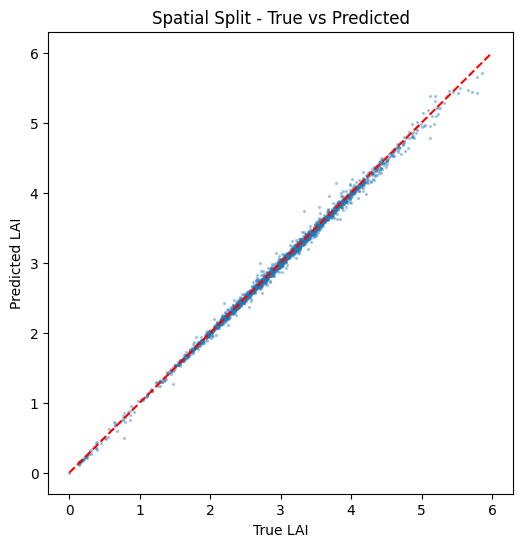

In [30]:
plt.figure(figsize=(6,6))
plt.scatter(y_te_spatial[::100], y_pred_spatial[::100], s=2, alpha=0.3)
plt.plot([0,6],[0,6],'r--')
plt.xlabel("True LAI")
plt.ylabel("Predicted LAI")
plt.title("Spatial Split - True vs Predicted")
plt.show()


In [31]:
print("Mean Lai Training: ", np.mean(y_tr_spatial))
print("Mean Lai Test (spatial split): ", np.mean(y_te_spatial))

Mean Lai Training:  2.801634
Mean Lai Test (spatial split):  2.9585757


# Cross Year Study

Cross-year X shape: (286326, 7)
Cross-year y shape: (286326,)


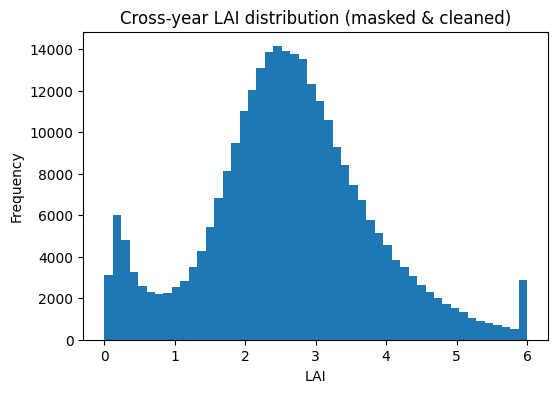

In [46]:
cross_year_safe = next(cross_path.glob("S2B_MSIL2A_20240823T101559_N0511_R065_T32TMR_20240823T145151.SAFE"))
cross_year_lai_path = Path("./CY_LAI_ROI_20m.tif")

cross_year_X, cross_year_scl = build_feature_stack(cross_year_safe, template)
cross_year_lai_clean, _ = load_and_clean_lai(cross_year_lai_path)

mask_cross_year = build_mask(cross_year_scl, cross_year_lai_clean, keep_classes=[4, 5, 6, 7])

X_cross_year = cross_year_X[mask_cross_year]
y_cross_year = cross_year_lai_clean[mask_cross_year]

print("Cross-year X shape:", X_cross_year.shape)
print("Cross-year y shape:", y_cross_year.shape)

plt.figure(figsize=(6,4))
plt.hist(y_cross_year, bins=50)
plt.xlabel("LAI")
plt.ylabel("Frequency")
plt.title("Cross-year LAI distribution (masked & cleaned)")
plt.show()


In [36]:
y_pred_cross_year = rf_spatial.predict(X_cross_year)

r2_cy = r2_score(y_cross_year, y_pred_cross_year)
rmse_cy = np.sqrt(mean_squared_error(y_cross_year, y_pred_cross_year))
bias_cy = np.mean(y_pred_cross_year - y_cross_year)

print("Cross-year R²:", r2_cy)
print("Cross-year RMSE:", rmse_cy)
print("Cross-year Bias:", bias_cy)


Cross-year R²: 0.8602691670598621
Cross-year RMSE: 0.4432018051666029
Cross-year Bias: -0.21725461967234583


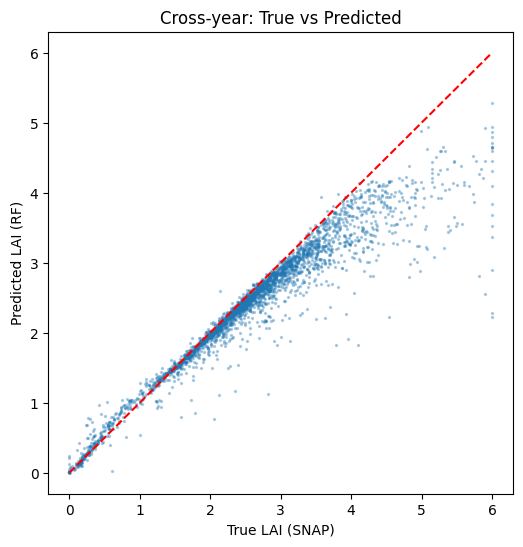

In [38]:
plt.figure(figsize=(6,6))
plt.scatter(y_cross_year[::100], y_pred_cross_year[::100], s=2, alpha=0.3)
plt.plot([0,6],[0,6],'r--')
plt.xlabel("True LAI (SNAP)")
plt.ylabel("Predicted LAI (RF)")
plt.title("Cross-year: True vs Predicted")
plt.show()


In [37]:
print("Mean LAI 2024:", np.mean(y_cross_year))
print("Mean prediction 2024:", np.mean(y_pred_cross_year))


Mean LAI 2024: 2.6201887
Mean prediction 2024: 2.4029341795015546



--- TRAIN (Jul 2021) ---
N pixels: 949831
Mean: 2.8427057
Std : 0.9514863
P50: 2.891
P75: 3.451
P90: 3.990
P95: 4.331
P99: 5.007
% LAI > 4: 0.0981237714919812
% LAI > 5: 0.010207078943517321

--- CROSS-YEAR (Aug 2024) ---
N pixels: 286326
Mean: 2.6201887
Std : 1.185647
P50: 2.600
P75: 3.307
P90: 4.107
P95: 4.670
P99: 5.888
% LAI > 4: 0.11348253389493096
% LAI > 5: 0.03265159293951649


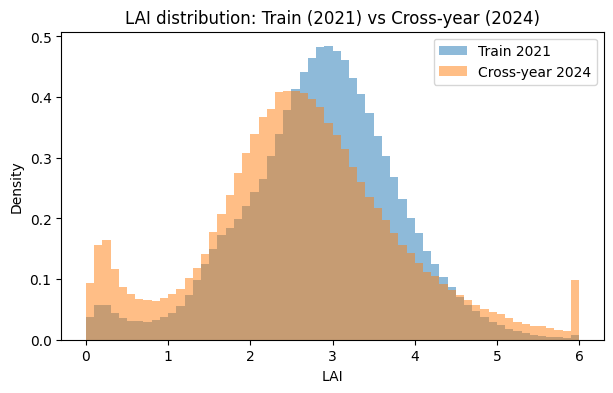

In [40]:
def summary_lai(y, name):
    y = np.asarray(y)
    print(f"\n--- {name} ---")
    print("N pixels:", y.size)
    print("Mean:", y.mean())
    print("Std :", y.std())
    for q in [50, 75, 90, 95, 99]:
        print(f"P{q}: {np.percentile(y, q):.3f}")
    print("% LAI > 4:", (y > 4).mean())
    print("% LAI > 5:", (y > 5).mean())

summary_lai(y_train, "TRAIN (Jul 2021)")
summary_lai(y_cross_year, "CROSS-YEAR (Aug 2024)")

plt.figure(figsize=(7,4))
plt.hist(y_train, bins=60, alpha=0.5, density=True, label="Train 2021")
plt.hist(y_cross_year, bins=60, alpha=0.5, density=True, label="Cross-year 2024")
plt.xlabel("LAI")
plt.ylabel("Density")
plt.title("LAI distribution: Train (2021) vs Cross-year (2024)")
plt.legend()
plt.show()


In [41]:
feature_names = ["B05","B06","B07","B8A","B11","B12","NDVI"]

def feature_summary(X, name):
    print(f"\n=== {name} feature summary ===")
    for i, f in enumerate(feature_names):
        v = X[:, i]
        print(f"{f:>4}  mean={v.mean():.4f}  std={v.std():.4f}  p1={np.percentile(v,1):.4f}  p99={np.percentile(v,99):.4f}")

feature_summary(X_train, "TRAIN (Jul 2021)")
feature_summary(X_cross_year, "CROSS-YEAR (Aug 2024)")



=== TRAIN (Jul 2021) feature summary ===
 B05  mean=0.2045  std=0.0281  p1=0.1612  p99=0.2964
 B06  mean=0.4585  std=0.0743  p1=0.2670  p99=0.6511
 B07  mean=0.5388  std=0.0939  p1=0.2854  p99=0.7652
 B8A  mean=0.5694  std=0.0980  p1=0.2956  p99=0.8029
 B11  mean=0.3325  std=0.0427  p1=0.2242  p99=0.4478
 B12  mean=0.2120  std=0.0341  p1=0.1597  p99=0.3398
NDVI  mean=0.5949  std=0.1063  p1=0.1294  p99=0.7013

=== CROSS-YEAR (Aug 2024) feature summary ===
 B05  mean=0.2159  std=0.0445  p1=0.1628  p99=0.3799
 B06  mean=0.4125  std=0.0791  p1=0.2598  p99=0.6709
 B07  mean=0.4970  std=0.1043  p1=0.2839  p99=0.8186
 B8A  mean=0.5399  std=0.1164  p1=0.2895  p99=0.8926
 B11  mean=0.3367  std=0.0564  p1=0.2051  p99=0.5120
 B12  mean=0.2182  std=0.0495  p1=0.1486  p99=0.4048
NDVI  mean=0.5011  std=0.1172  p1=0.0778  p99=0.6428


/var/folders/q7/2mxs7f6529550js05ydzbwfm0000gn/T/ipykernel_60483/525931123.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


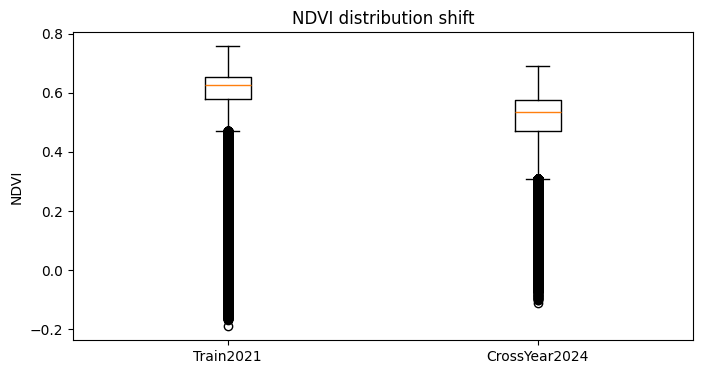

In [42]:
import pandas as pd

df = pd.DataFrame({
    "NDVI": np.concatenate([X_train[:, -1], X_cross_year[:, -1]]),
    "B8A":  np.concatenate([X_train[:, 3],  X_cross_year[:, 3]]),
    "B12":  np.concatenate([X_train[:, 5],  X_cross_year[:, 5]]),
    "set":  ["Train2021"] * X_train.shape[0] + ["CrossYear2024"] * X_cross_year.shape[0]
})

plt.figure(figsize=(8,4))
plt.boxplot(
    [df[df["set"]=="Train2021"]["NDVI"], df[df["set"]=="CrossYear2024"]["NDVI"]],
    labels=["Train2021","CrossYear2024"]
)
plt.title("NDVI distribution shift")
plt.ylabel("NDVI")
plt.show()


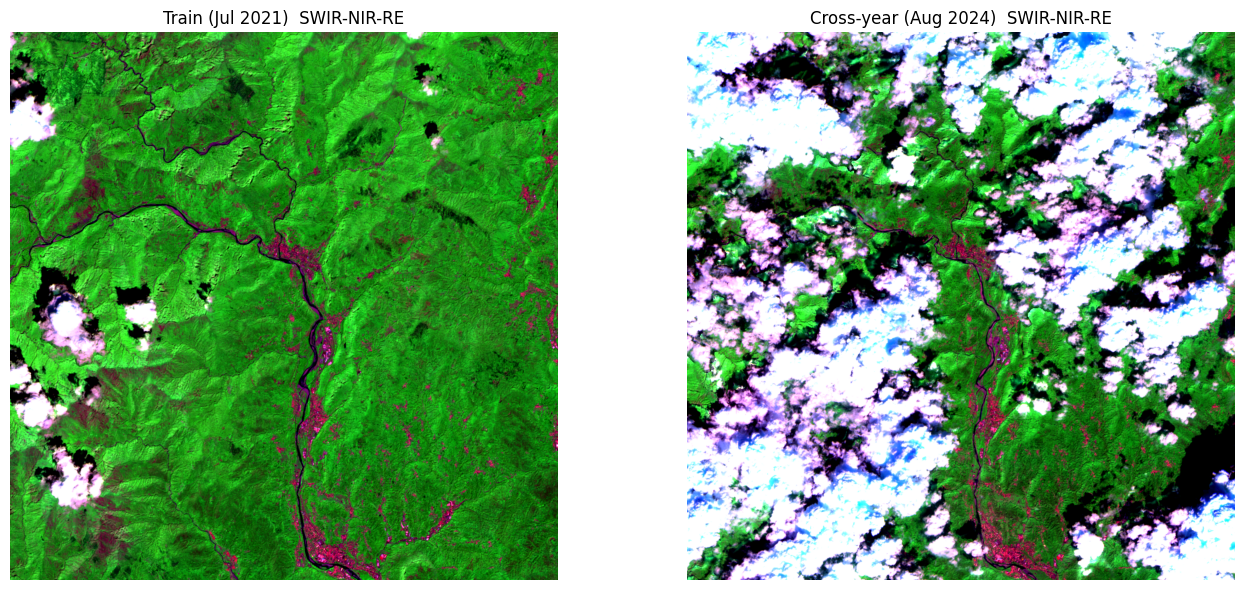

In [44]:
channels = ("B12","B8A","B05")  # R,G,B

# stats calcolate SOLO sul training (reference), così tutti hanno stesso stretch
ref_stats = compute_stretch_stats(training_X, channels, pmin=2, pmax=98)

img_train, _ = make_composite_image(training_X, channels, stretch_stats=ref_stats)
img_2024,  _ = make_composite_image(cross_year_X, channels, stretch_stats=ref_stats)

plot_composites(
    [img_train, img_2024],
    ["Train (Jul 2021)  SWIR-NIR-RE", "Cross-year (Aug 2024)  SWIR-NIR-RE"],
    figsize=(14,6)
)

# Cross Season Study

In [ ]:
# --- CROSS-SEASON (Oct 2021) paths ---
cross_season_safe = next(cross_path.glob("S2A_MSIL2A_20211013T101951_N0500_R065_T32TMR_20230115T052455.SAFE"))
cross_season_lai_path = Path("./CS_LAI_ROI_20m.tif")   # <-- metti il nome reale del tuo file

# --- Extract features + SCL ---
cross_season_X, cross_season_scl = build_feature_stack(cross_season_safe, template)

# --- Load + clean LAI ---
cross_season_lai_clean, _ = load_and_clean_lai(cross_season_lai_path)

# --- Valid mask ---
mask_cross_season = build_mask(cross_season_scl, cross_season_lai_clean, keep_classes=[4,5,6,7])

# --- Flatten to samples ---
X_cross_season = cross_season_X[mask_cross_season]
y_cross_season = cross_season_lai_clean[mask_cross_season]

print("Cross-season X:", X_cross_season.shape)
print("Cross-season y:", y_cross_season.shape)
print("Cross-season LAI mean:", np.mean(y_cross_season))
print("Cross-season % LAI>4:", np.mean(y_cross_season > 4))

Cross-season LAI shape: (1000, 940)


ValueError: operands could not be broadcast together with shapes (1000,1000) (1000,940) 

In [ ]:
y_pred_cross_season = rf_spatial.predict(X_cross_season)

r2_cs = r2_score(y_cross_season, y_pred_cross_season)
rmse_cs = np.sqrt(mean_squared_error(y_cross_season, y_pred_cross_season))
bias_cs = np.mean(y_pred_cross_season - y_cross_season)

print("Cross-season R²:", r2_cs)
print("Cross-season RMSE:", rmse_cs)
print("Cross-season Bias:", bias_cs)


In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(y_cross_season[::100], y_pred_cross_season[::100], s=2, alpha=0.3)
plt.plot([0,6],[0,6],'r--')
plt.xlabel("True LAI (SNAP)")
plt.ylabel("Predicted LAI (RF)")
plt.title("Cross-season (Oct 2021): True vs Predicted")
plt.show()
